# LungVision AI — Phase 7 Final Evaluation (Validation-Only)

**Purpose:** finish the remaining Phase 7 analysis without training any model and without touching the official test split.

This notebook:
1. verifies mounted datasets, checkpoint inventory, manifest integrity and patient separation;
2. reads the preserved training histories and builds a defensible experiment comparison;
3. prepares per-disease validation metrics, ROC/PR curves, threshold selection and calibration outputs;
4. saves a report bundle under `/kaggle/working/lungvision_phase7_final_evaluation`.

## Critical reproducibility requirement

This notebook embeds the exact model architecture and deterministic preprocessing definitions from the uploaded Phase 7 recovery training notebook. It verifies checkpoint metadata before validation inference.

**No training is performed. The official test split is excluded throughout.**


**Runtime fix:** `DEVICE` and `gc` are initialized in the model/source cell before the architecture smoke test, so the source-verification cell does not depend on a later inference cell having run first.


## 0. Configuration

In [1]:
from pathlib import Path
import os, json, hashlib, warnings, time, math, platform
import numpy as np
import pandas as pd

# Resolve Kaggle mounts robustly. Kaggle's displayed dataset title and its
# internal slug/path are not always identical.
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_ROOT = Path("/kaggle/working")

DATASET_ROOT = Path("/kaggle/input/datasets/babulkumar07/lungvision-ai-phase-7-recovery-run-result")
PROJECT_ROOT = DATASET_ROOT / "lungvision_phase7"

def find_phase7_root():
    candidates = []
    if PROJECT_ROOT.exists():
        candidates.append(PROJECT_ROOT)
    if INPUT_ROOT.exists():
        for p in INPUT_ROOT.rglob("lungvision_phase7"):
            if p.is_dir():
                candidates.append(p)
        # The screenshot may expose the artifact folder itself as the dataset root.
        for p in INPUT_ROOT.rglob("checkpoints"):
            if p.is_dir() and (p.parent / "manifests").is_dir() and (p.parent / "results").is_dir():
                candidates.append(p.parent)
    for candidate in candidates:
        if (candidate / "checkpoints").is_dir() and (candidate / "manifests").is_dir() and (candidate / "results").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate a Phase 7 folder containing checkpoints/, manifests/, and results/. "
        "Attach the LungVision Phase 7 recovery dataset as a Kaggle input."
    )

PROJECT_ROOT = find_phase7_root()
DATASET_ROOT = PROJECT_ROOT.parent
NIH_ROOT = Path("/kaggle/input/datasets/nih-chest-xrays/data")
if not (NIH_ROOT / "Data_Entry_2017.csv").exists():
    matches = list(INPUT_ROOT.rglob("Data_Entry_2017.csv"))
    if matches:
        NIH_ROOT = matches[0].parent

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
MANIFEST_DIR = PROJECT_ROOT / "manifests"
RESULTS_DIR = PROJECT_ROOT / "results"
OUTPUT_DIR = Path("/kaggle/working/lungvision_phase7_final_evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABELS = [
    "Cardiomegaly", "Edema", "Consolidation",
    "Pneumonia", "Atelectasis", "Pneumothorax"
]
EXPECTED_SPLIT_SHA256 = "ca0d2ed9efe6c4a2b479b25d5c10e762bdffcda1eeaf5672fcca499e6ddb7a09"

EXPERIMENTS = {
    "msd121_224_weighted_bce_direct": {
        "checkpoint": "msd121_224_weighted_bce_direct.pth",
        "history": "msd121_224_weighted_bce_direct_history.csv",
        "image_size": 224, "loss": "weighted_bce", "preprocessing": "direct"
    },
    "msd121_224_weighted_bce_letterbox": {
        "checkpoint": "msd121_224_weighted_bce_letterbox.pth",
        "history": "msd121_224_weighted_bce_letterbox_history.csv",
        "image_size": 224, "loss": "weighted_bce", "preprocessing": "letterbox"
    },
    "msd121_224_focal_direct": {
        "checkpoint": "msd121_224_focal_direct.pth",
        "history": "msd121_224_focal_direct_history.csv",
        "image_size": 224, "loss": "focal", "preprocessing": "direct"
    },
    "msd121_224_focal_letterbox": {
        "checkpoint": "msd121_224_focal_letterbox.pth",
        "history": None, "image_size": 224, "loss": "focal", "preprocessing": "letterbox"
    },
    "msd121_512_weighted_bce_direct": {
        "checkpoint": "msd121_512_weighted_bce_direct.pth",
        "history": "msd121_512_weighted_bce_direct_history.csv",
        "image_size": 512, "loss": "weighted_bce", "preprocessing": "direct"
    }
}

print("Dataset root:", DATASET_ROOT, DATASET_ROOT.exists())
print("NIH root:", NIH_ROOT, NIH_ROOT.exists())
for p in [CHECKPOINT_DIR, MANIFEST_DIR, RESULTS_DIR]:
    print(p, p.exists())
assert DATASET_ROOT.exists() and NIH_ROOT.exists(), "Attach both Kaggle datasets before continuing."
assert all(p.exists() for p in [CHECKPOINT_DIR, MANIFEST_DIR, RESULTS_DIR]), "Missing Phase 7 artifact folder."


Dataset root: /kaggle/input/datasets/babulkumar07/lungvision-ai-phase-7-recovery-run-result True
NIH root: /kaggle/input/datasets/nih-chest-xrays/data True
/kaggle/input/datasets/babulkumar07/lungvision-ai-phase-7-recovery-run-result/lungvision_phase7/checkpoints True
/kaggle/input/datasets/babulkumar07/lungvision-ai-phase-7-recovery-run-result/lungvision_phase7/manifests True
/kaggle/input/datasets/babulkumar07/lungvision-ai-phase-7-recovery-run-result/lungvision_phase7/results True


## 1. Runtime and file inventory

In [2]:
import torch
from PIL import Image

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

for folder in [CHECKPOINT_DIR, MANIFEST_DIR, RESULTS_DIR]:
    print(f"\\n### {folder.name}")
    for f in sorted(folder.rglob("*")):
        if f.is_file():
            print(f"{f.relative_to(PROJECT_ROOT)} | {f.stat().st_size/1024**2:.2f} MB")

checkpoint_files = sorted(CHECKPOINT_DIR.glob("*.pth"))
assert len(checkpoint_files) >= 5, f"Expected at least 5 best checkpoints; found {len(checkpoint_files)}"


Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
\n### checkpoints
checkpoints/msd121_224_focal_direct.pth | 31.37 MB
checkpoints/msd121_224_focal_letterbox.pth | 31.38 MB
checkpoints/msd121_224_weighted_bce_direct.pth | 31.38 MB
checkpoints/msd121_224_weighted_bce_letterbox.pth | 31.38 MB
checkpoints/msd121_512_weighted_bce_direct.pth | 31.38 MB
checkpoints/msd121_512_weighted_bce_direct_last.pth | 72.73 MB
\n### manifests
manifests/nih_phase7_split_manifest.csv | 18.51 MB
manifests/split_summary.json | 0.00 MB
\n### results
results/msd121_224_focal_direct_history.csv | 0.00 MB
results/msd121_224_weighted_bce_direct_history.csv | 0.00 MB
results/msd121_224_weighted_bce_letterbox_history.csv | 0.00 MB
results/msd121_512_weighted_bce_direct_history.csv | 0.00 MB
results/phase7_validation_summary.csv | 0.00 MB
results/preserved_checkpoint_audit.csv | 0.00 MB
results/training_runs.csv | 0.00 MB


## 2. Manifest verification (never load the test images)

In [3]:
manifest_path = MANIFEST_DIR / "nih_phase7_split_manifest.csv"
summary_path = MANIFEST_DIR / "split_summary.json"
manifest = pd.read_csv(manifest_path)
split_summary = json.loads(summary_path.read_text())

required_cols = {"Image Index", "Patient ID", "View Position", "split", *LABELS}
missing = required_cols - set(manifest.columns)
assert not missing, f"Manifest is missing columns: {missing}"

print("Rows:", len(manifest))
print("Duplicate image names:", int(manifest["Image Index"].duplicated().sum()))
print("Split counts:\\n", manifest["split"].value_counts())
print("Patient counts by split:\\n", manifest.groupby("split")["Patient ID"].nunique())
print("Summary split SHA256:", split_summary.get("split_sha256"))
print("Expected split SHA256:", EXPECTED_SPLIT_SHA256)

assert manifest["Image Index"].is_unique, "Duplicate image names in manifest."
assert set(manifest["split"].unique()) <= {"train", "validation", "test"}
assert split_summary.get("split_sha256") == EXPECTED_SPLIT_SHA256
assert split_summary.get("labels") == LABELS

patient_sets = {s: set(manifest.loc[manifest.split == s, "Patient ID"].astype(str)) for s in ["train", "validation", "test"]}
for a, b in [("train","validation"), ("train","test"), ("validation","test")]:
    overlap = patient_sets[a] & patient_sets[b]
    print(f"{a} ∩ {b} patients:", len(overlap))
    assert not overlap, f"Patient leakage between {a} and {b}"

expected_counts = {"train":73023, "validation":13501, "test":25596}
actual_counts = manifest["split"].value_counts().to_dict()
assert actual_counts == expected_counts, f"Unexpected split counts: {actual_counts}"

# Verify validation paths only. Do not enumerate or read official test images.
val_df = manifest.loc[manifest.split == "validation"].copy()
missing_val = [p for p in val_df["image_path"].head(1000) if not Path(p).exists()]
print("Missing paths among first 1,000 validation rows:", len(missing_val))
assert not missing_val, "Some sampled validation paths are missing. Check NIH dataset mount."


Rows: 112120
Duplicate image names: 0
Split counts:\n split
train         73023
test          25596
validation    13501
Name: count, dtype: int64
Patient counts by split:\n split
test           2797
train         23806
validation     4202
Name: Patient ID, dtype: int64
Summary split SHA256: ca0d2ed9efe6c4a2b479b25d5c10e762bdffcda1eeaf5672fcca499e6ddb7a09
Expected split SHA256: ca0d2ed9efe6c4a2b479b25d5c10e762bdffcda1eeaf5672fcca499e6ddb7a09
train ∩ validation patients: 0
train ∩ test patients: 0
validation ∩ test patients: 0
Missing paths among first 1,000 validation rows: 0


## 3. Checkpoint metadata and tensor audit

In [4]:
# weights_only=False is required for the checkpoint's ordinary metadata dict in this trusted user-provided artifact.
# Only load checkpoints from your own Kaggle dataset.
checkpoint_metadata = []
for exp_id, cfg in EXPERIMENTS.items():
    path = CHECKPOINT_DIR / cfg["checkpoint"]
    if not path.exists():
        print("MISSING:", exp_id, path)
        continue
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    state = ckpt.get("model_state_dict")
    assert isinstance(state, dict), f"No model_state_dict in {path.name}"
    bad = [k for k,v in state.items() if not torch.is_tensor(v) or not torch.isfinite(v).all()]
    assert not bad, f"Non-finite/non-tensor state entries in {path.name}: {bad[:5]}"
    meta = {
        "experiment_id": exp_id,
        "checkpoint": path.name,
        "size_mb": round(path.stat().st_size/1024**2, 2),
        "epoch": ckpt.get("epoch"),
        "best_val_macro_auroc": ckpt.get("best_val_macro_auroc"),
        "image_size": ckpt.get("image_size"),
        "preprocessing": ckpt.get("preprocessing"),
        "labels_match": ckpt.get("labels") == LABELS,
        "split_hash_match": ckpt.get("split_sha256") == EXPECTED_SPLIT_SHA256,
        "state_tensor_count": len(state),
        "all_state_tensors_finite": True,
        "config": ckpt.get("config", {})
    }
    assert meta["labels_match"], f"Label order mismatch in {path.name}"
    assert meta["split_hash_match"], f"Split hash mismatch in {path.name}"
    checkpoint_metadata.append(meta)

checkpoint_audit = pd.DataFrame(checkpoint_metadata)
display(checkpoint_audit)
checkpoint_audit.to_csv(OUTPUT_DIR / "checkpoint_metadata_audit.csv", index=False)


,experiment_id,checkpoint,size_mb,epoch,best_val_macro_auroc,image_size,preprocessing,labels_match,split_hash_match,state_tensor_count,all_state_tensors_finite,config
0,msd121_224_weighted_bce_direct,msd121_224_weighted_bce_direct.pth,31.38,4,0.819726,224,direct,True,True,749,True,{'experiment_id': 'msd121_224_weighted_bce_dir...
1,msd121_224_weighted_bce_letterbox,msd121_224_weighted_bce_letterbox.pth,31.38,4,0.818934,224,letterbox,True,True,749,True,{'experiment_id': 'msd121_224_weighted_bce_let...
2,msd121_224_focal_direct,msd121_224_focal_direct.pth,31.37,5,0.814352,224,direct,True,True,749,True,"{'experiment_id': 'msd121_224_focal_direct', '..."
3,msd121_224_focal_letterbox,msd121_224_focal_letterbox.pth,31.38,2,0.798783,224,letterbox,True,True,749,True,{'experiment_id': 'msd121_224_focal_letterbox'...
4,msd121_512_weighted_bce_direct,msd121_512_weighted_bce_direct.pth,31.38,4,0.778568,512,direct,True,True,749,True,{'experiment_id': 'msd121_512_weighted_bce_dir...


## 4. Training-history comparison

In [5]:
summary_csv = RESULTS_DIR / "phase7_validation_summary.csv"
history_summary = pd.read_csv(summary_csv)
display(history_summary)

history_frames = {}
for exp_id, cfg in EXPERIMENTS.items():
    if cfg["history"] is None:
        continue
    p = RESULTS_DIR / cfg["history"]
    if p.exists():
        h = pd.read_csv(p)
        history_frames[exp_id] = h
        print(f"\\n{exp_id}: {len(h)} history rows")
        display(h.tail(3))

# Recompute best epoch from actual histories where available.
history_best = []
for exp_id, h in history_frames.items():
    metric = "val_macro_auroc"
    idx = h[metric].astype(float).idxmax()
    row = h.loc[idx]
    history_best.append({
        "experiment_id": exp_id,
        "history_best_auroc": float(row[metric]),
        "history_best_epoch": int(row["epoch"]),
        "history_rows": len(h),
        "best_val_loss": float(h.loc[h["val_loss"].astype(float).idxmin(), "val_loss"])
    })
history_best_df = pd.DataFrame(history_best)
display(history_best_df)
history_best_df.to_csv(OUTPUT_DIR / "history_best_epoch_summary.csv", index=False)


,experiment_id,image_size,loss,preprocessing,checkpoint_exists,history_exists,best_val_macro_auroc,best_epoch,epochs_in_history,history_best_val_macro_auroc
0,msd121_224_weighted_bce_direct,224,weighted_bce,direct,True,True,0.819726,4.0,7,0.819726
1,msd121_224_weighted_bce_letterbox,224,weighted_bce,letterbox,True,True,0.818934,4.0,7,0.818934
2,msd121_224_focal_direct,224,focal,direct,True,True,0.814352,5.0,8,0.814352
3,msd121_224_focal_letterbox,224,focal,letterbox,True,False,0.798783,2.0,0,NaN
4,msd121_512_weighted_bce_direct,512,weighted_bce,direct,True,True,0.778568,4.0,5,0.778568
5,msd121_512_weighted_bce_letterbox,512,weighted_bce,letterbox,False,False,NaN,NaN,0,NaN
6,msd121_512_focal_direct,512,focal,direct,False,False,NaN,NaN,0,NaN
7,msd121_512_focal_letterbox,512,focal,letterbox,False,False,NaN,NaN,0,NaN


\nmsd121_224_weighted_bce_direct: 7 history rows


,epoch,train_loss,val_loss,val_macro_auroc,lr,epoch_seconds,smoke_test
4,5,0.892576,1.412407,0.813595,0.00010,1711.109110,False
5,6,0.800816,1.630241,0.815993,0.00005,1718.318701,False
6,7,0.574069,2.179260,0.801001,0.00005,1742.527062,False


\nmsd121_224_weighted_bce_letterbox: 7 history rows


,epoch,train_loss,val_loss,val_macro_auroc,lr,epoch_seconds,smoke_test
4,5,0.889402,1.400837,0.813066,0.00010,1735.655002,False
5,6,0.799873,1.605846,0.808327,0.00005,1732.471044,False
6,7,0.571710,2.263476,0.799708,0.00005,1722.147591,False


\nmsd121_224_focal_direct: 8 history rows


,epoch,train_loss,val_loss,val_macro_auroc,lr,epoch_seconds,smoke_test
5,6,0.223646,0.449579,0.808021,0.00010,1712.568514,False
6,7,0.199719,0.470458,0.807179,0.00005,1695.536135,False
7,8,0.145995,0.903133,0.793456,0.00005,1717.515765,False


\nmsd121_512_weighted_bce_direct: 5 history rows


,epoch,train_loss,val_loss,val_macro_auroc,val_macro_auprc,lr,epoch_seconds,validation_seconds,smoke_test
2,3,2.977964,3.216273,0.755122,0.101405,0.0001,7534.453810,487.688248,False
3,4,2.845081,3.210165,0.778568,0.120089,0.0001,7540.628184,495.112417,False
4,5,2.728117,2.995711,0.774407,0.117954,0.0001,7538.059858,495.063534,False


,experiment_id,history_best_auroc,history_best_epoch,history_rows,best_val_loss
0,msd121_224_weighted_bce_direct,0.819726,4,7,1.133851
1,msd121_224_weighted_bce_letterbox,0.818934,4,7,1.115478
2,msd121_224_focal_direct,0.814352,5,8,0.288671
3,msd121_512_weighted_bce_direct,0.778568,4,5,2.774734


## 5. Evidence-based experiment ranking

In [6]:
ranking = history_summary.loc[history_summary["checkpoint_exists"].astype(str).str.lower().isin(["true","1"])].copy()
ranking["best_val_macro_auroc"] = pd.to_numeric(ranking["best_val_macro_auroc"], errors="coerce")
ranking = ranking.sort_values("best_val_macro_auroc", ascending=False)
display(ranking[["experiment_id","image_size","loss","preprocessing","best_val_macro_auroc","best_epoch","history_exists"]])
ranking.to_csv(OUTPUT_DIR / "experiment_ranking.csv", index=False)

best_row = ranking.iloc[0]
print("Leading validation candidate:", best_row["experiment_id"])
print("Recorded best validation macro-AUROC:", best_row["best_val_macro_auroc"])
print("This is a provisional selection, not official test performance.")


,experiment_id,image_size,loss,preprocessing,best_val_macro_auroc,best_epoch,history_exists
0,msd121_224_weighted_bce_direct,224,weighted_bce,direct,0.819726,4.0,True
1,msd121_224_weighted_bce_letterbox,224,weighted_bce,letterbox,0.818934,4.0,True
2,msd121_224_focal_direct,224,focal,direct,0.814352,5.0,True
3,msd121_224_focal_letterbox,224,focal,letterbox,0.798783,2.0,False
4,msd121_512_weighted_bce_direct,512,weighted_bce,direct,0.778568,4.0,True


Leading validation candidate: msd121_224_weighted_bce_direct
Recorded best validation macro-AUROC: 0.8197257752392035
This is a provisional selection, not official test performance.


## 6. Exact model and preprocessing implementation

The next cell contains the original `MultiScaleDenseNet121`, `Letterbox`, ImageNet normalization and `build_transform` definitions copied from the Phase 7 recovery training notebook. `build_eval_transform` delegates directly to that original transform function.

The official test split is not loaded by the inference code. Only `val_df` is used.


In [7]:
# Exact Phase 7 source copied from the original recovery training notebook.
# Source cells: preprocessing (training cell 9) and architecture (training cell 11).
# Required imports are explicit so this cell is self-contained.

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import gc

# Define the runtime device BEFORE the architecture smoke test.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    print("Evaluation device:", torch.cuda.get_device_name(0), flush=True)
else:
    print("Evaluation device: CPU", flush=True)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

class Letterbox:
    def __init__(self, size, fill=(0,0,0)):
        self.size = int(size)
        self.fill = fill
    def __call__(self, image):
        image = image.convert("RGB")
        w, h = image.size
        scale = min(self.size / w, self.size / h)
        nw, nh = max(1, round(w*scale)), max(1, round(h*scale))
        image = image.resize((nw, nh), Image.Resampling.BILINEAR)
        canvas = Image.new("RGB", (self.size, self.size), self.fill)
        left = (self.size - nw) // 2
        top = (self.size - nh) // 2
        canvas.paste(image, (left, top))
        return canvas

def build_transform(size, preprocessing):
    if preprocessing == "direct":
        geometry = transforms.Resize((size, size), interpolation=transforms.InterpolationMode.BILINEAR)
    elif preprocessing == "letterbox":
        geometry = Letterbox(size)
    else:
        raise ValueError(preprocessing)
    return transforms.Compose([
        geometry,
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ])

class NIHXrayDataset(Dataset):
    def __init__(self, frame, size, preprocessing):
        self.frame = frame.reset_index(drop=True)
        self.transform = build_transform(size, preprocessing)
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row.image_path) as im:
            image = im.convert("RGB")
        image = self.transform(image)
        target = torch.tensor(row[LABELS].to_numpy(dtype=np.float32), dtype=torch.float32)
        return image, target

def make_loaders(size, preprocessing, batch_size):
    train_ds = NIHXrayDataset(train_df, size, preprocessing)
    val_ds = NIHXrayDataset(val_df, size, preprocessing)
    test_ds = NIHXrayDataset(test_df, size, preprocessing)
    common = dict(num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=NUM_WORKERS > 0)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=False, **common)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, **common)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, **common)
    return train_loader, val_loader, test_loader

class MultiScaleDenseNet121(nn.Module):
    def __init__(self, pretrained=True, dropout=0.25):
        super().__init__()
        weights = models.DenseNet121_Weights.DEFAULT if pretrained else None
        base = models.densenet121(weights=weights)
        f = base.features

        # DenseNet121 feature stages: stem, dense block 1, transition 1,
        # dense block 2, transition 2, dense block 3, transition 3, dense block 4.
        self.stem = nn.Sequential(f.conv0, f.norm0, f.relu0, f.pool0)
        self.block1 = f.denseblock1
        self.trans1 = f.transition1
        self.block2 = f.denseblock2
        self.trans2 = f.transition2
        self.block3 = f.denseblock3
        self.trans3 = f.transition3
        self.block4 = f.denseblock4
        self.final_norm = f.norm5

        # DenseNet channels after stages: 256, 512, 1024; final: 1024.
        self.lat2 = nn.Conv2d(256, 128, kernel_size=1)
        self.lat3 = nn.Conv2d(512, 128, kernel_size=1)
        self.lat4 = nn.Conv2d(1024, 128, kernel_size=1)
        self.fuse = nn.Sequential(
            nn.Conv2d(128*3, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True)
        )
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.dropout = nn.Dropout(dropout)
        # Decoupled disease heads: each disease has its own classifier.
        self.heads = nn.ModuleList([
            nn.Linear(512, 1) for _ in LABELS
        ])

    def forward(self, x):
        x = self.stem(x)
        p2 = self.block1(x)       # 256 channels
        x = self.trans1(p2)
        p3 = self.block2(x)       # 512 channels
        x = self.trans2(p3)
        p4 = self.block3(x)       # 1024 channels
        x = self.trans3(p4)
        x = self.block4(x)
        x = self.final_norm(x)
        # Keep P2/P3/P4 spatial maps aligned to P2 resolution.
        target_size = p2.shape[-2:]
        l2 = self.lat2(p2)
        l3 = F.interpolate(self.lat3(p3), size=target_size, mode="bilinear", align_corners=False)
        l4 = F.interpolate(self.lat4(p4), size=target_size, mode="bilinear", align_corners=False)
        fused = self.fuse(torch.cat([l2, l3, l4], dim=1))
        pooled = torch.cat([self.avg_pool(fused), self.max_pool(fused)], dim=1).flatten(1)
        pooled = self.dropout(pooled)
        return torch.cat([head(pooled) for head in self.heads], dim=1)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

model_check = MultiScaleDenseNet121(pretrained=False).to(DEVICE)
dummy = torch.randn(1, 3, 512, 512, device=DEVICE)
with torch.no_grad():
    out = model_check(dummy)
assert out.shape == (1, 6), out.shape
print("512x512 model smoke output:", out.shape, "| trainable parameters:", count_parameters(model_check), flush=True)
del model_check, dummy, out
gc.collect()
if DEVICE.type == "cuda": torch.cuda.empty_cache()

def build_eval_transform(image_size: int, preprocessing: str):
    """Use the exact deterministic Phase 7 training transform."""
    return build_transform(size=int(image_size), preprocessing=preprocessing)


# Source verification: architecture structure, transform modes and output contract.
assert callable(build_eval_transform)
assert isinstance(build_eval_transform(224, "direct"), transforms.Compose)
assert isinstance(build_eval_transform(224, "letterbox"), transforms.Compose)
assert isinstance(build_eval_transform(512, "direct"), transforms.Compose)

MODEL_SOURCE_CONFIRMED = True
print("Verified: original MultiScaleDenseNet121 and Phase 7 validation transforms loaded.")


Evaluation device: Tesla T4
512x512 model smoke output: torch.Size([1, 6]) | trainable parameters: 8071942
Verified: original MultiScaleDenseNet121 and Phase 7 validation transforms loaded.


## 7. Validation-only inference and per-disease metrics (unlocks after source gate)

In [8]:
# This cell is intentionally downstream of the source gate above.
# It assumes the exact model class and build_eval_transform are defined above.

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, precision_score, recall_score, f1_score, brier_score_loss
)
from PIL import Image
import matplotlib.pyplot as plt

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16 if DEVICE.type == "cuda" else 8
NUM_WORKERS = 2

class LungVisionValidationDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, idx):
        r = self.frame.iloc[idx]
        with Image.open(r["image_path"]) as im:
            im = im.convert("RGB")
            x = self.transform(im)
        y = r[LABELS].to_numpy(dtype=np.float32)
        return x, torch.tensor(y, dtype=torch.float32), r["Image Index"]

def load_model_for_experiment(exp_id, cfg):
    ckpt_path = CHECKPOINT_DIR / cfg["checkpoint"]
    ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    # Check checkpoint metadata before loading its weights.
    assert int(ckpt.get("image_size", cfg["image_size"])) == int(cfg["image_size"])
    assert ckpt.get("preprocessing", cfg["preprocessing"]) == cfg["preprocessing"]
    assert ckpt.get("labels") == LABELS
    model = MultiScaleDenseNet121(pretrained=False)
    missing, unexpected = model.load_state_dict(ckpt["model_state_dict"], strict=True)
    assert not missing and not unexpected
    model.to(DEVICE).eval()
    return model, ckpt

def infer_validation(exp_id, cfg):
    transform = build_eval_transform(cfg["image_size"], cfg["preprocessing"])
    ds = LungVisionValidationDataset(val_df, transform)
    # 512x512 multiscale inference needs a smaller batch on a Tesla T4.
    inference_batch_size = 4 if int(cfg["image_size"]) == 512 else 16
    loader = DataLoader(ds, batch_size=inference_batch_size, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"))
    model, ckpt = load_model_for_experiment(exp_id, cfg)
    all_logits, all_targets, all_names = [], [], []
    with torch.inference_mode():
        for xb, yb, names in loader:
            xb = xb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            if isinstance(logits, (tuple, list)):
                logits = logits[0]
            assert logits.ndim == 2 and logits.shape[1] == len(LABELS)
            all_logits.append(logits.detach().float().cpu().numpy())
            all_targets.append(yb.numpy())
            all_names.extend(list(names))
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    logits = np.concatenate(all_logits)
    y_true = np.concatenate(all_targets).astype(int)
    # Check training code's output convention. The expected convention here is raw logits.
    y_prob = 1.0 / (1.0 + np.exp(-np.clip(logits, -40, 40)))
    return y_true, y_prob, all_names

# Start with all five best checkpoints. No training and no test split.
predictions = {}
for exp_id, cfg in EXPERIMENTS.items():
    if (CHECKPOINT_DIR / cfg["checkpoint"]).exists():
        print("Validation inference:", exp_id)
        predictions[exp_id] = infer_validation(exp_id, cfg)


Validation inference: msd121_224_weighted_bce_direct
Validation inference: msd121_224_weighted_bce_letterbox
Validation inference: msd121_224_focal_direct
Validation inference: msd121_224_focal_letterbox
Validation inference: msd121_512_weighted_bce_direct


## 8. Per-disease AUROC / AUPRC and ROC / PR curves

,experiment_id,label,positive_count,negative_count,auroc,auprc,threshold,precision,recall_sensitivity,f1,specificity,tn,fp,fn,tp
0,msd121_224_weighted_bce_direct,Cardiomegaly,270,13231,0.885725,0.232019,0.5,0.117836,0.677778,0.200768,0.896455,11861,1370,87,183
1,msd121_224_weighted_bce_direct,Edema,209,13292,0.875816,0.144588,0.5,0.074181,0.736842,0.134792,0.855402,11370,1922,55,154
2,msd121_224_weighted_bce_direct,Consolidation,444,13057,0.794522,0.109084,0.5,0.069522,0.815315,0.128119,0.628935,8212,4845,82,362
3,msd121_224_weighted_bce_direct,Pneumonia,139,13362,0.759125,0.030007,0.5,0.035062,0.525180,0.065736,0.849648,11353,2009,66,73
4,msd121_224_weighted_bce_direct,Atelectasis,1345,12156,0.793636,0.304700,0.5,0.209115,0.753903,0.327414,0.684518,8321,3835,331,1014
5,msd121_224_weighted_bce_direct,Pneumothorax,467,13034,0.809516,0.152861,0.5,0.119162,0.584582,0.197970,0.845174,11016,2018,194,273
6,msd121_224_weighted_bce_letterbox,Cardiomegaly,270,13231,0.890676,0.220642,0.5,0.140164,0.633333,0.229530,0.920716,12182,1049,99,171
7,msd121_224_weighted_bce_letterbox,Edema,209,13292,0.870634,0.132806,0.5,0.080700,0.684211,0.144372,0.877445,11663,1629,66,143
8,msd121_224_weighted_bce_letterbox,Consolidation,444,13057,0.796096,0.122449,0.5,0.071935,0.799550,0.131995,0.649230,8477,4580,89,355
9,msd121_224_weighted_bce_letterbox,Pneumonia,139,13362,0.751137,0.035673,0.5,0.031861,0.410072,0.059129,0.870379,11630,1732,82,57


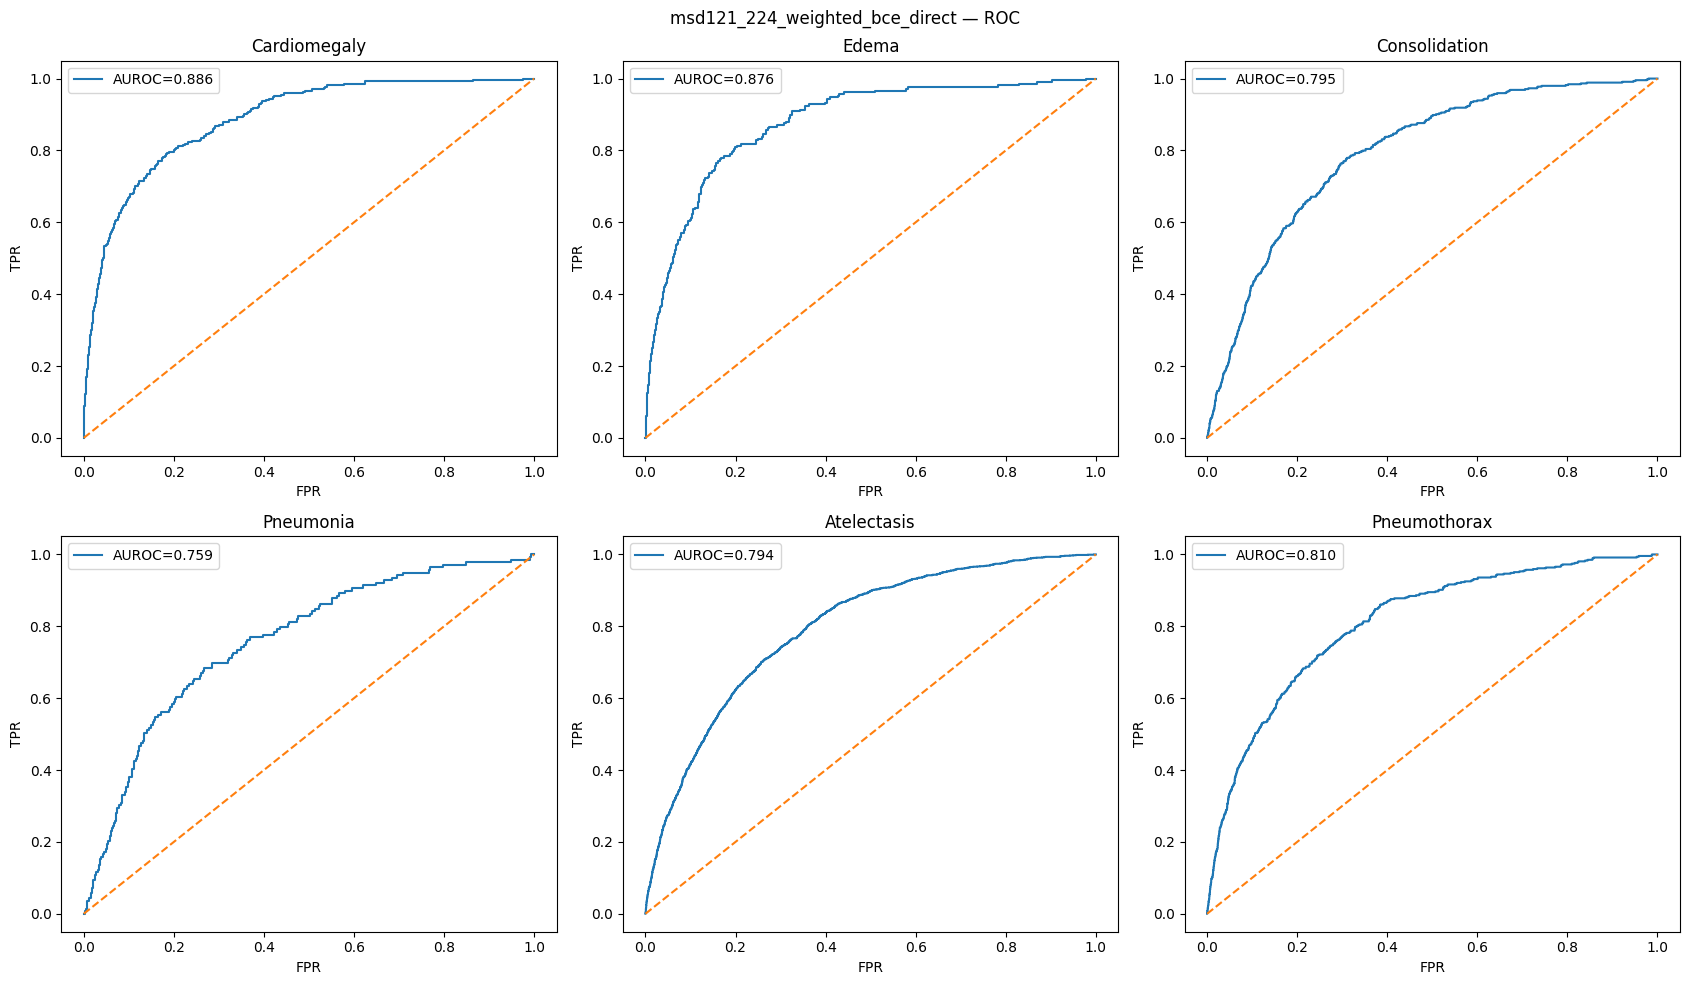

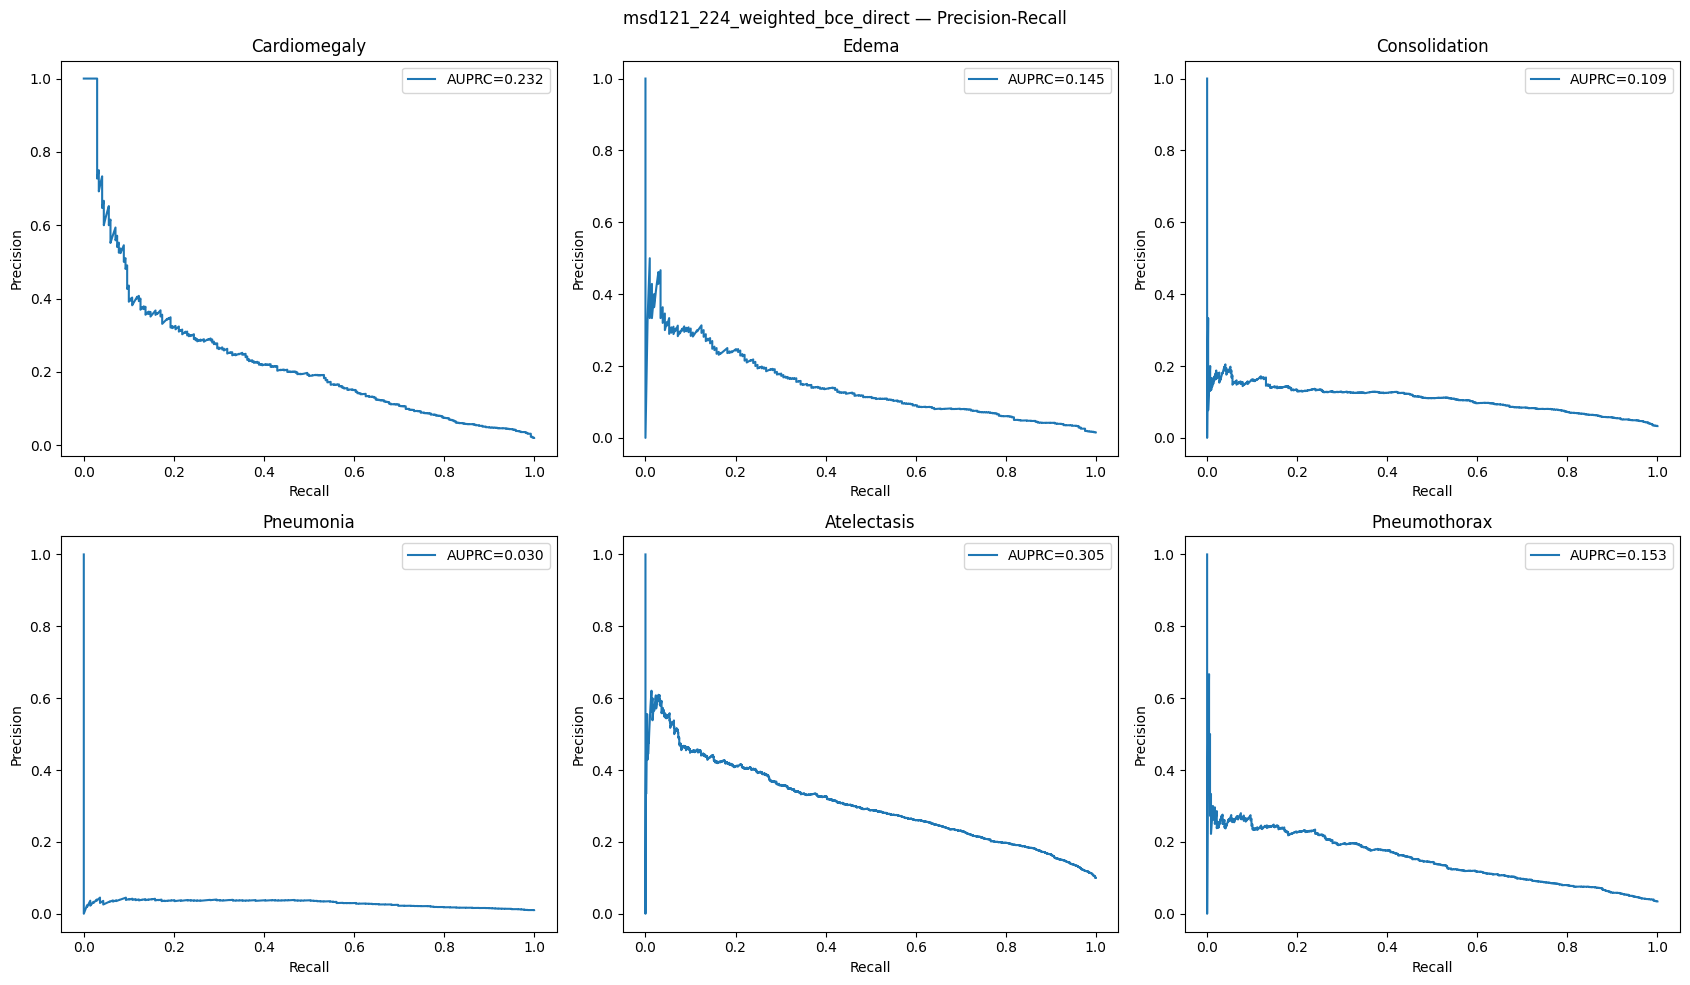

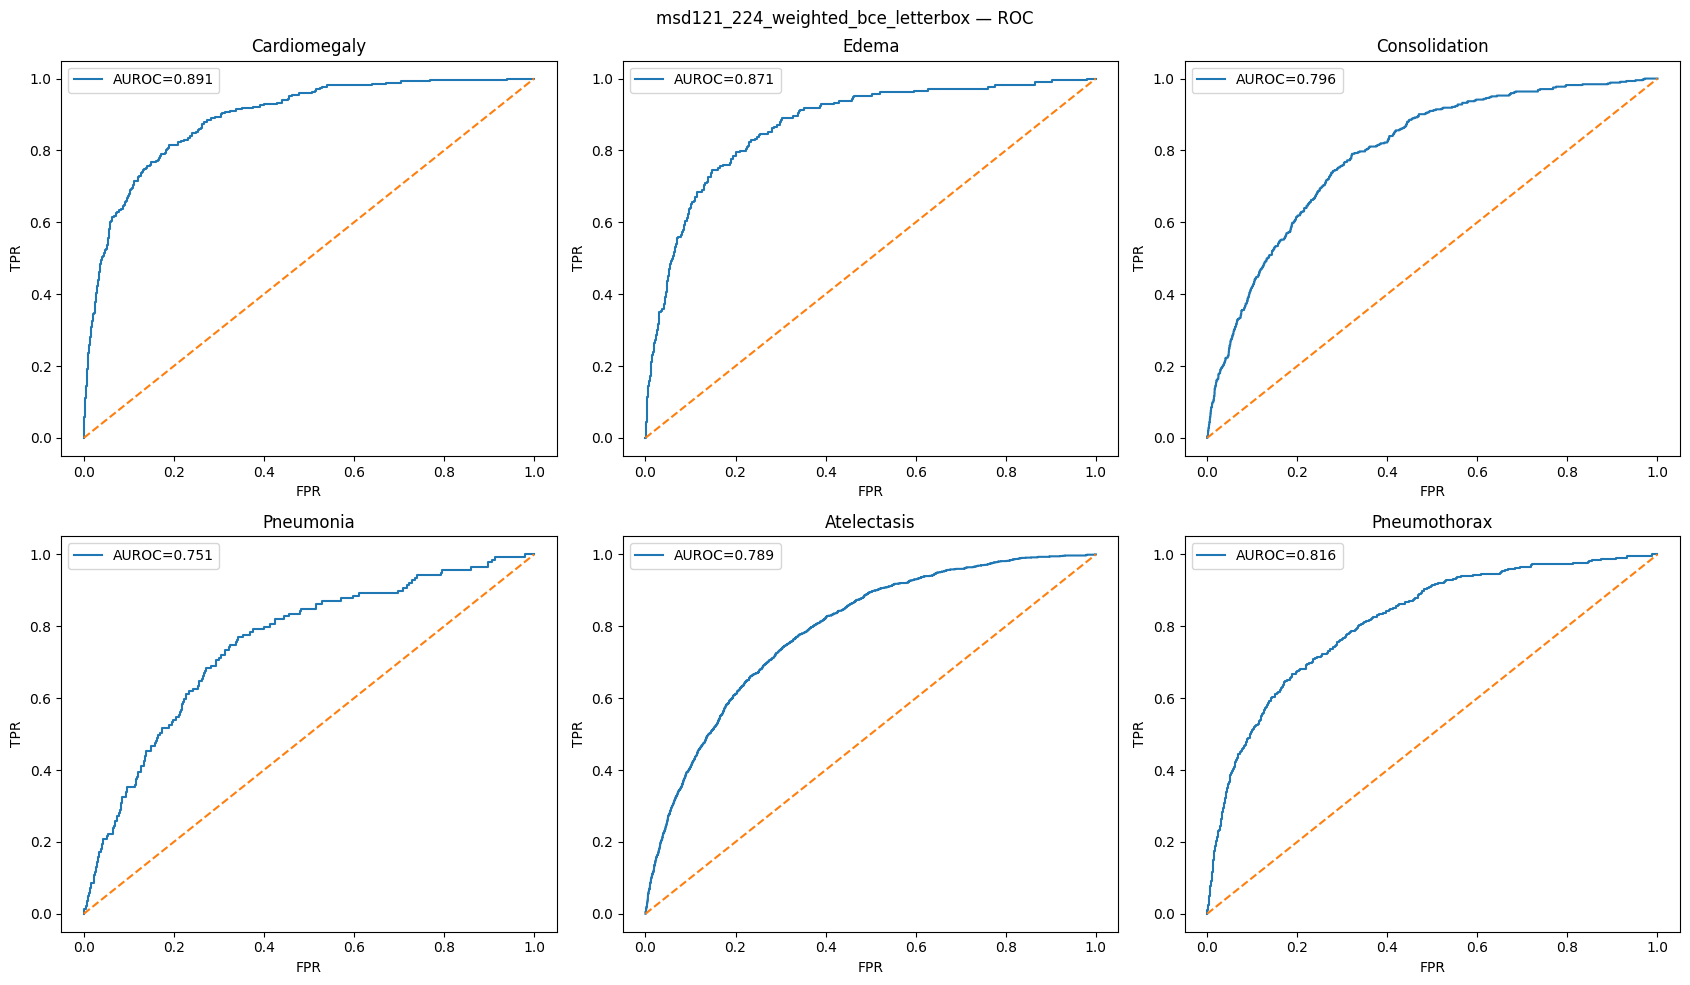

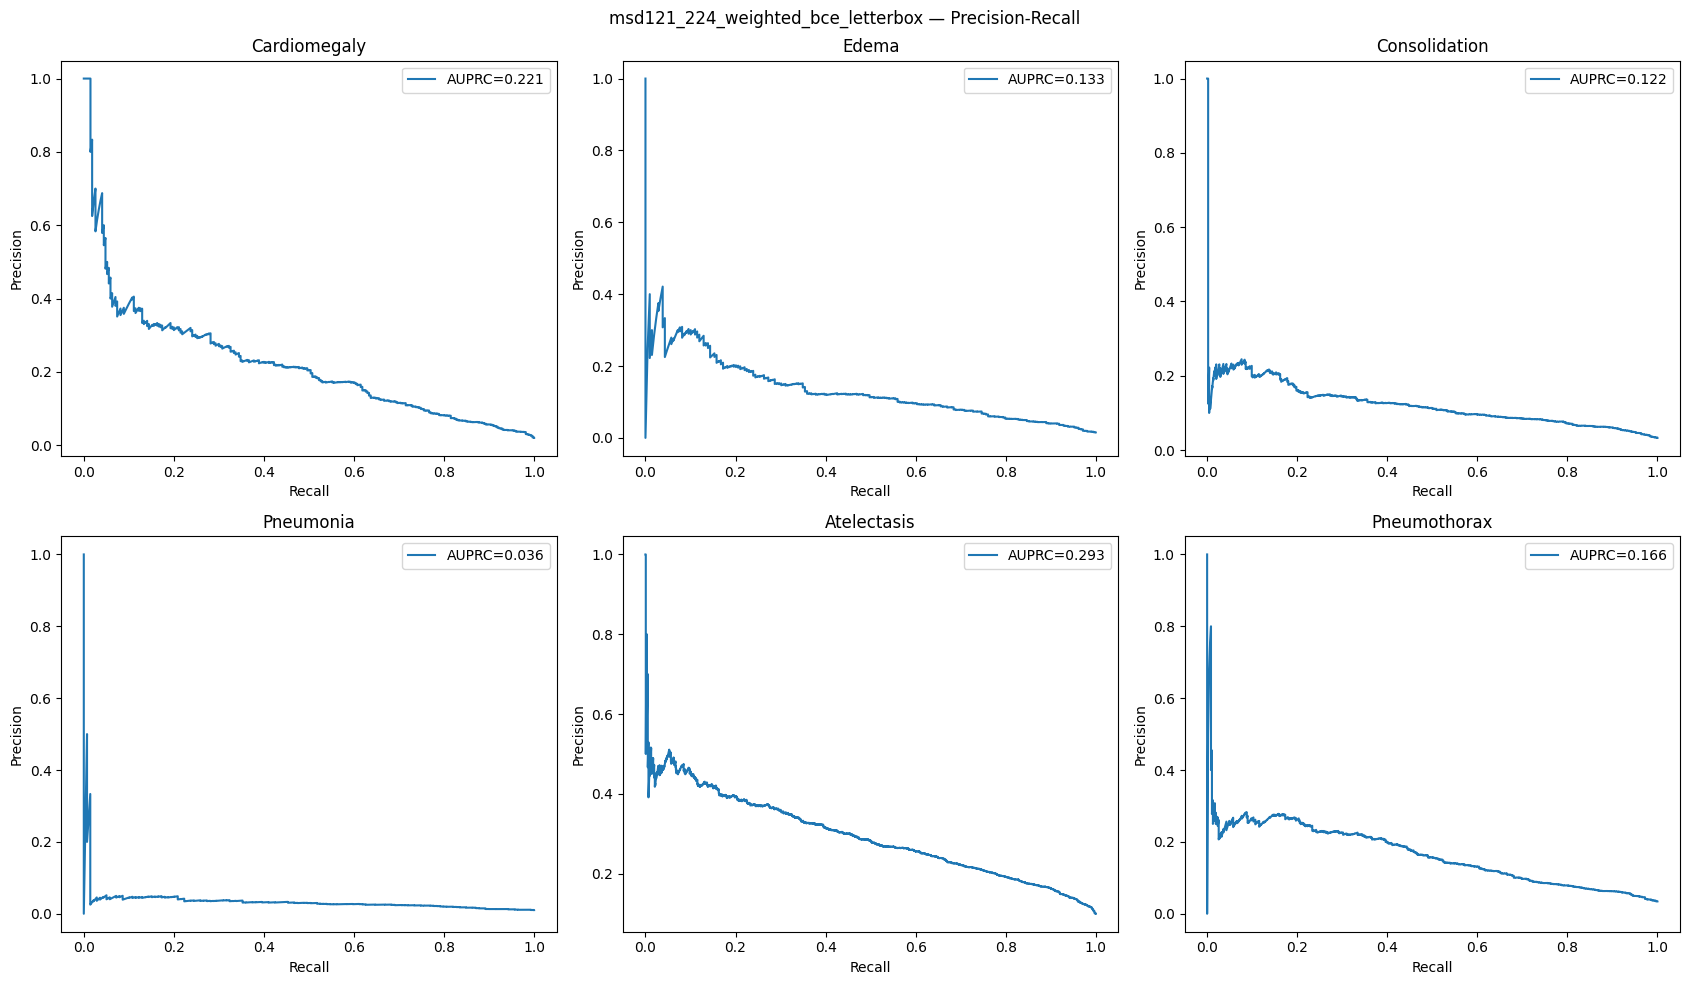

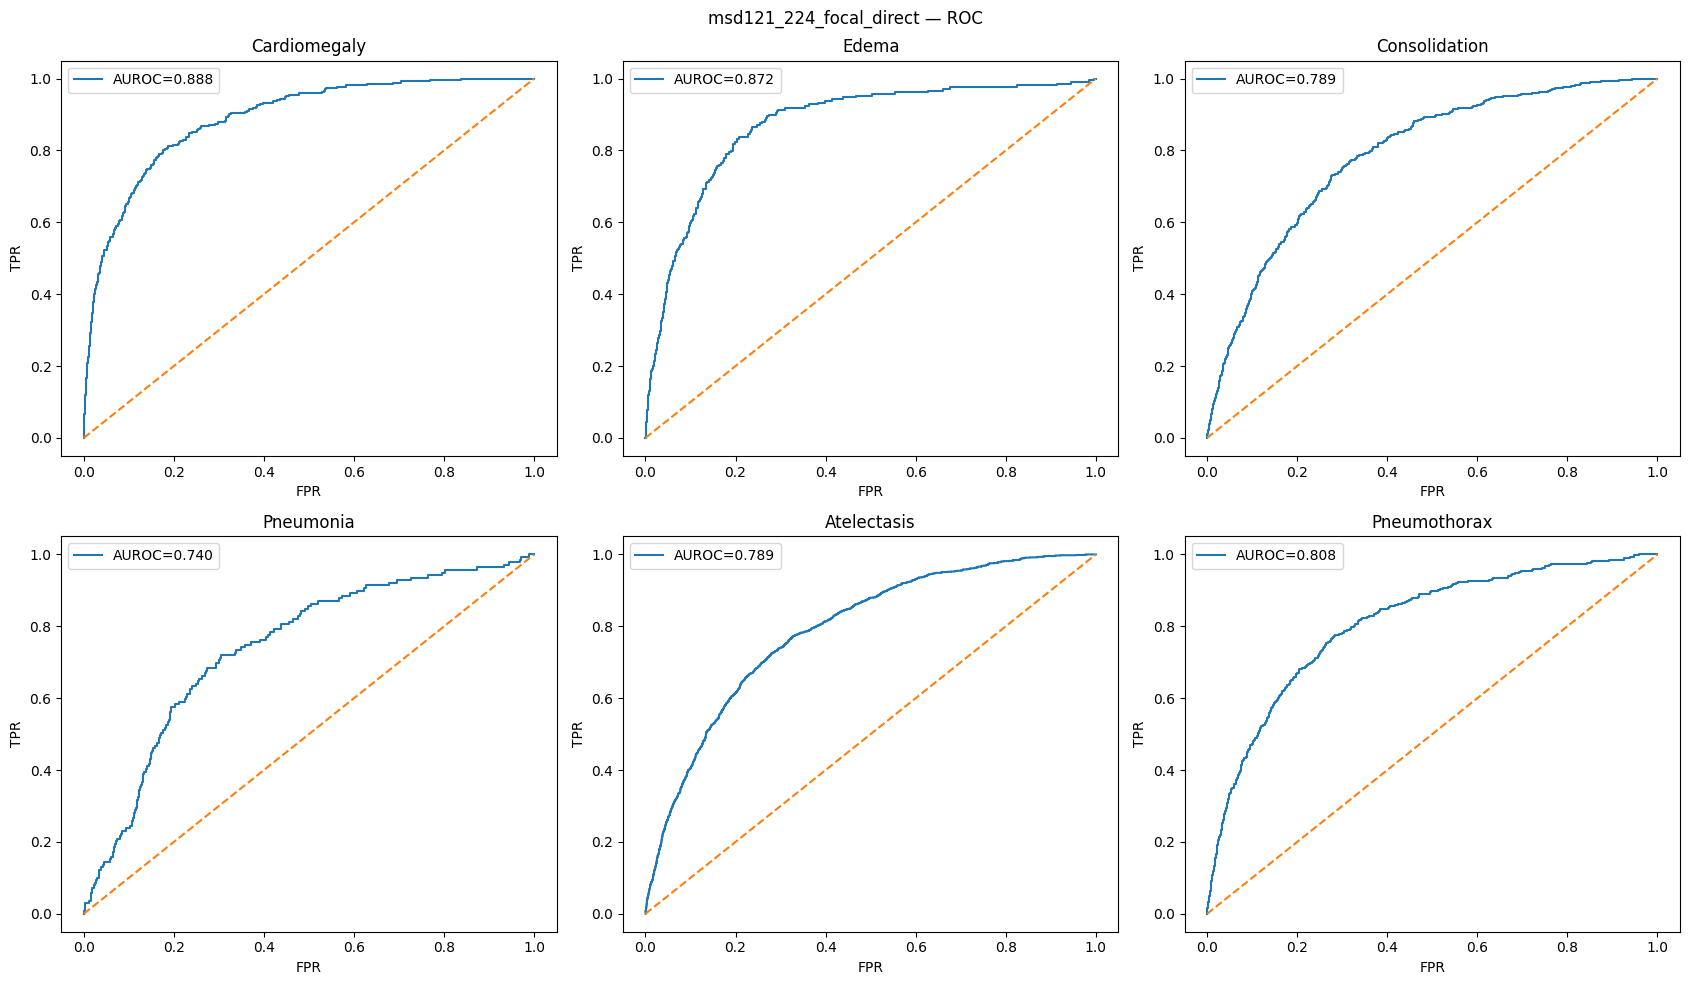

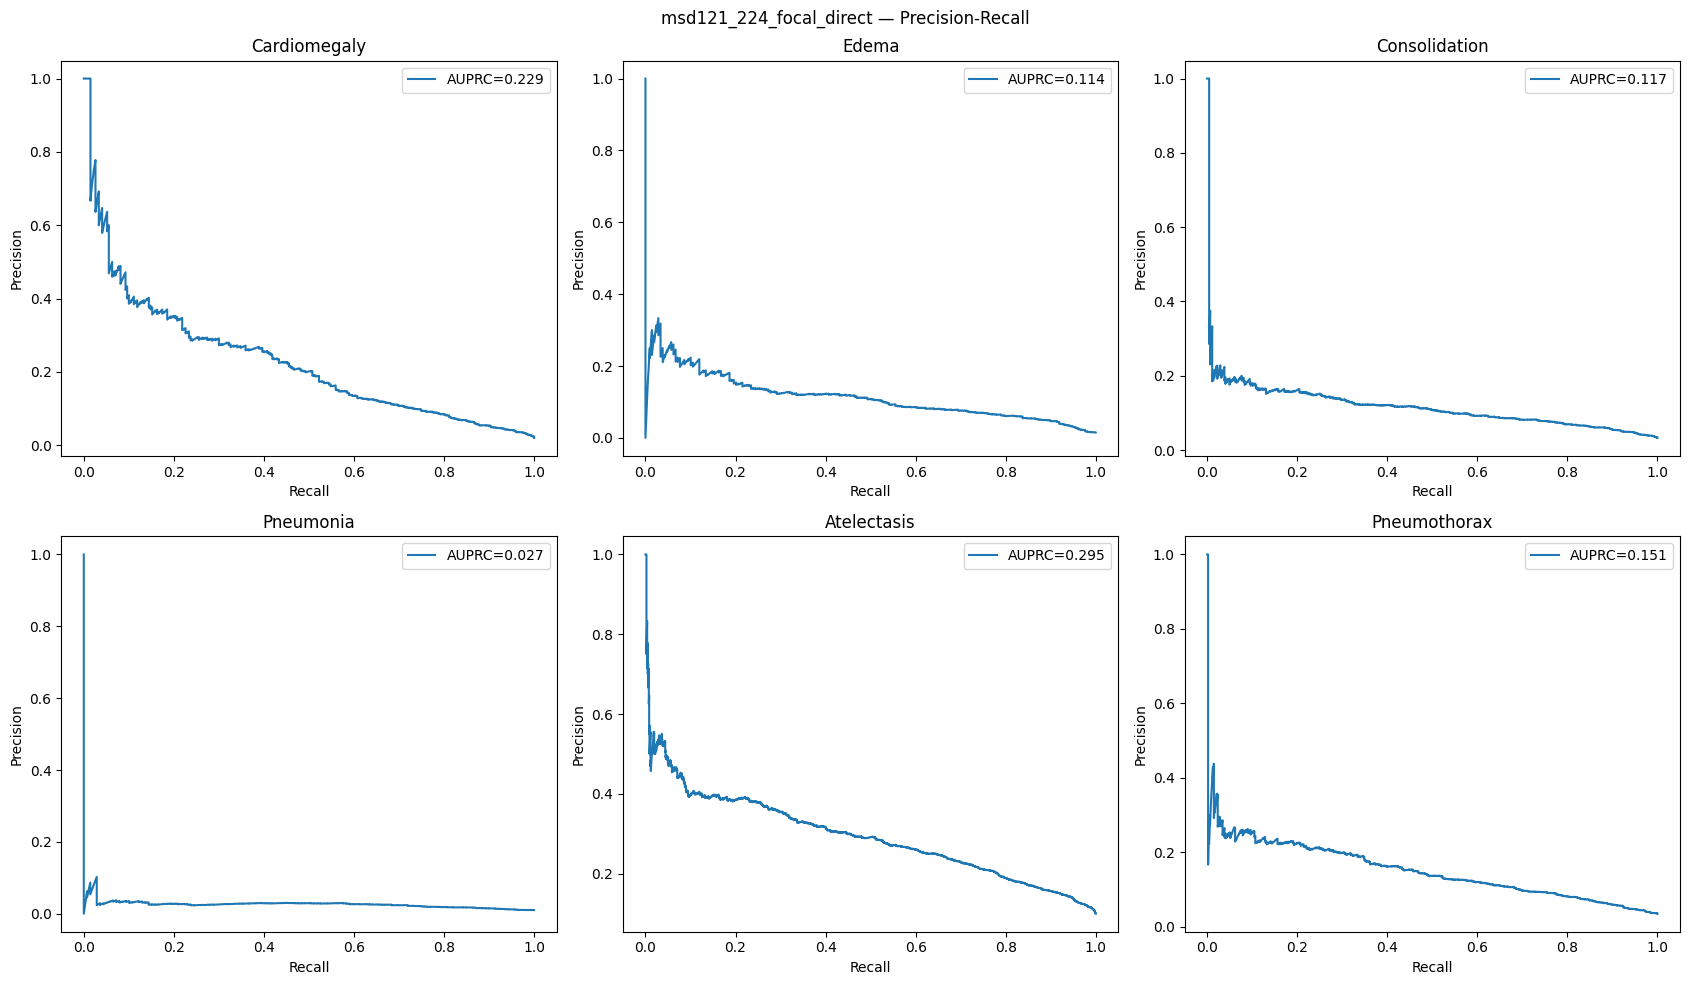

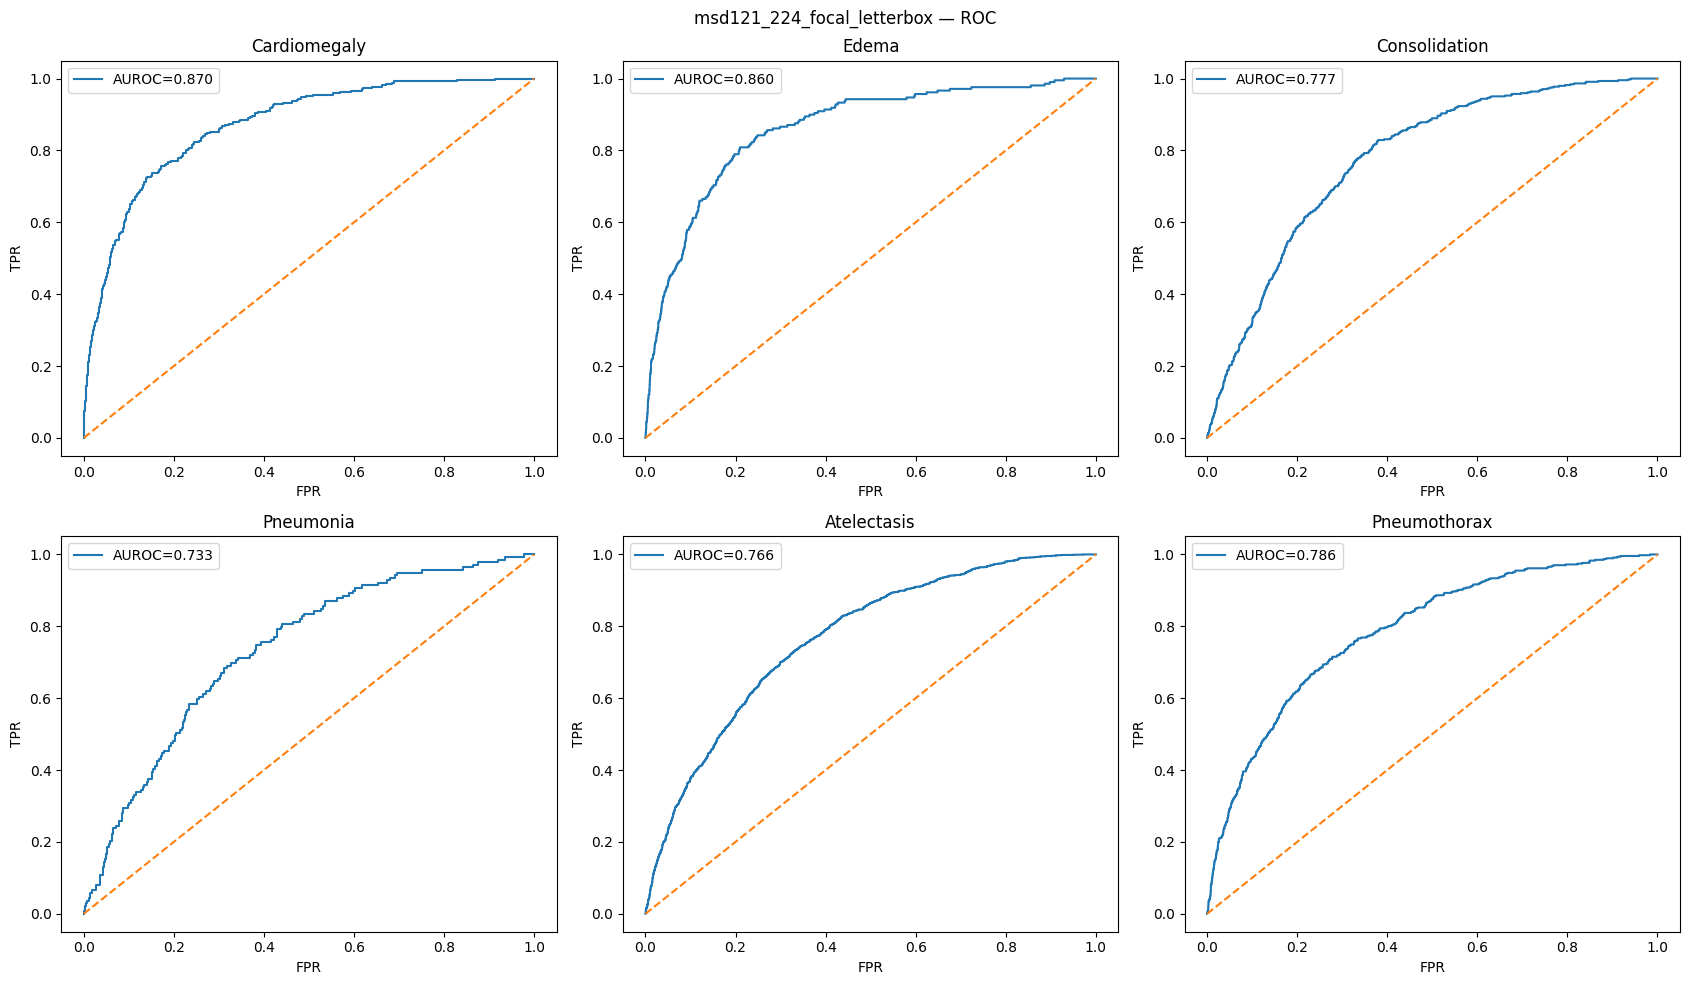

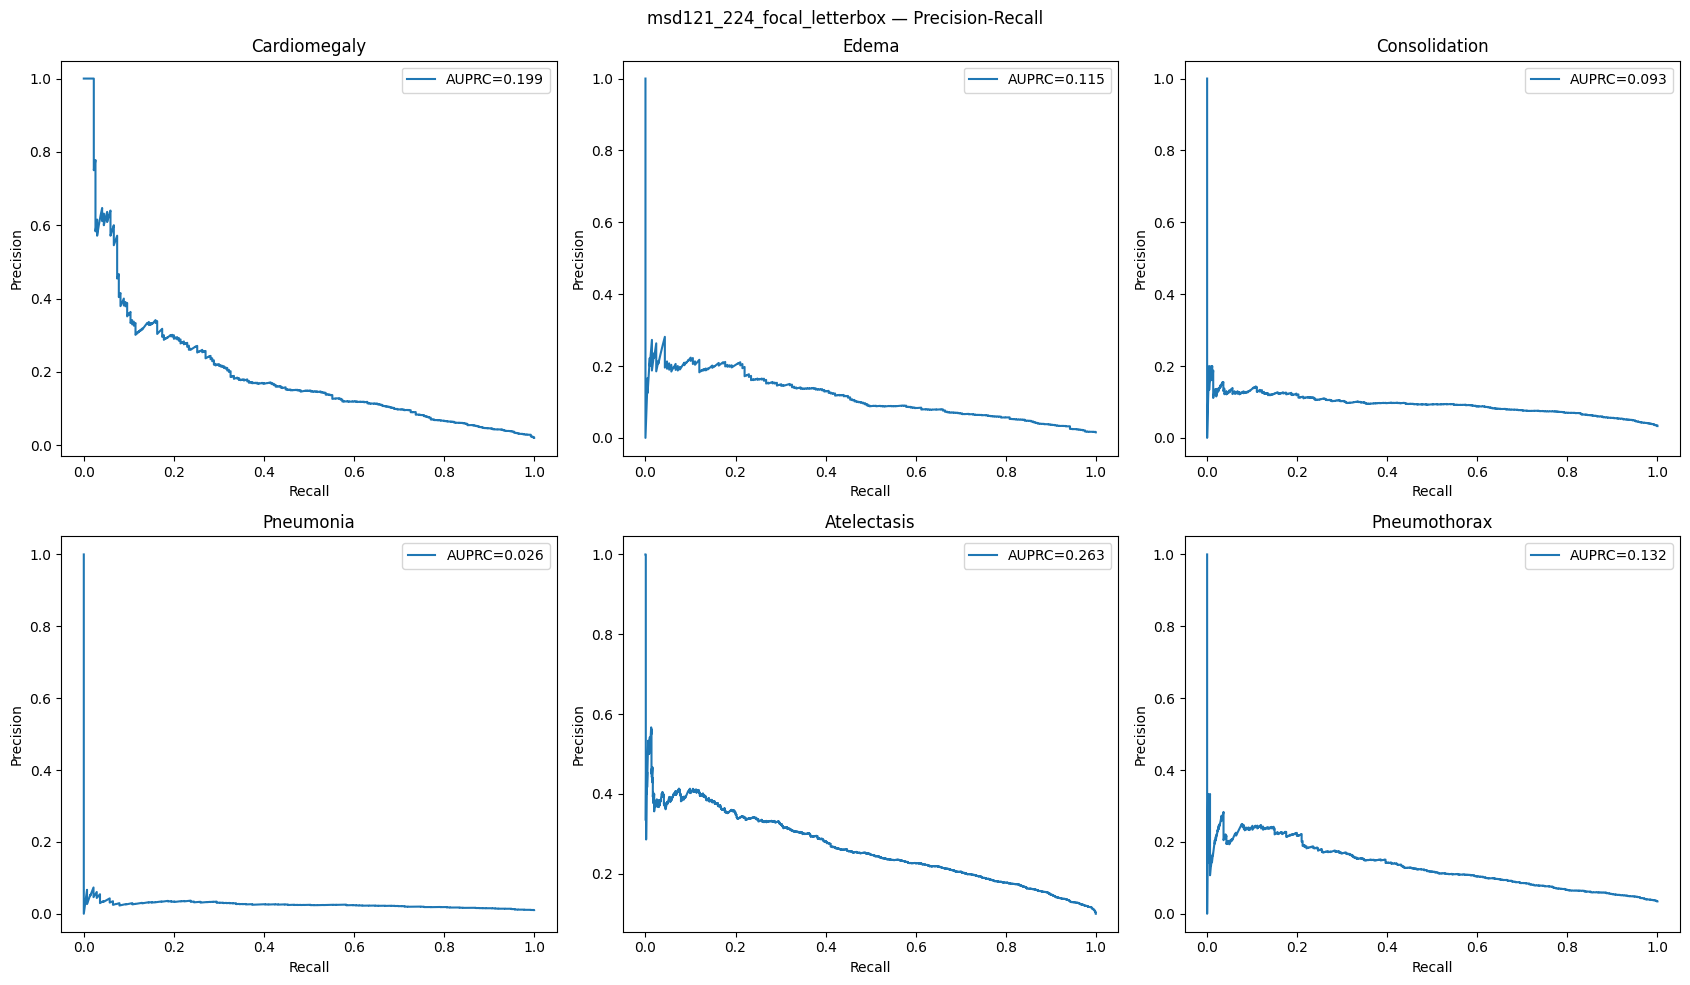

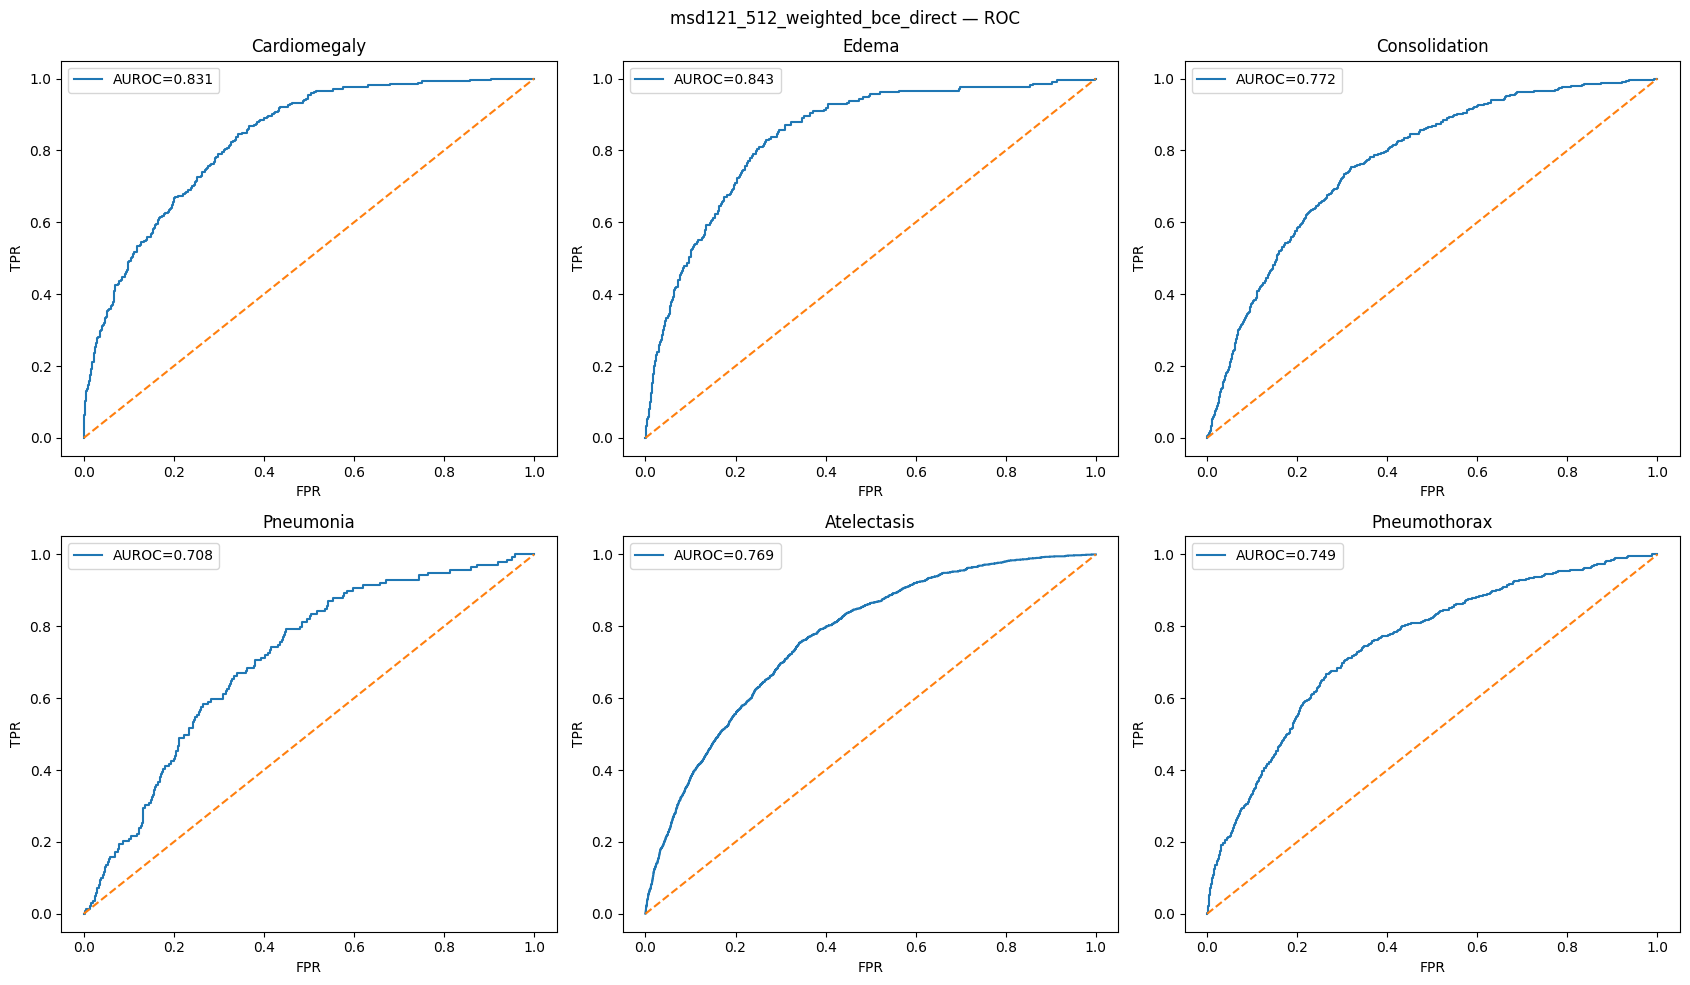

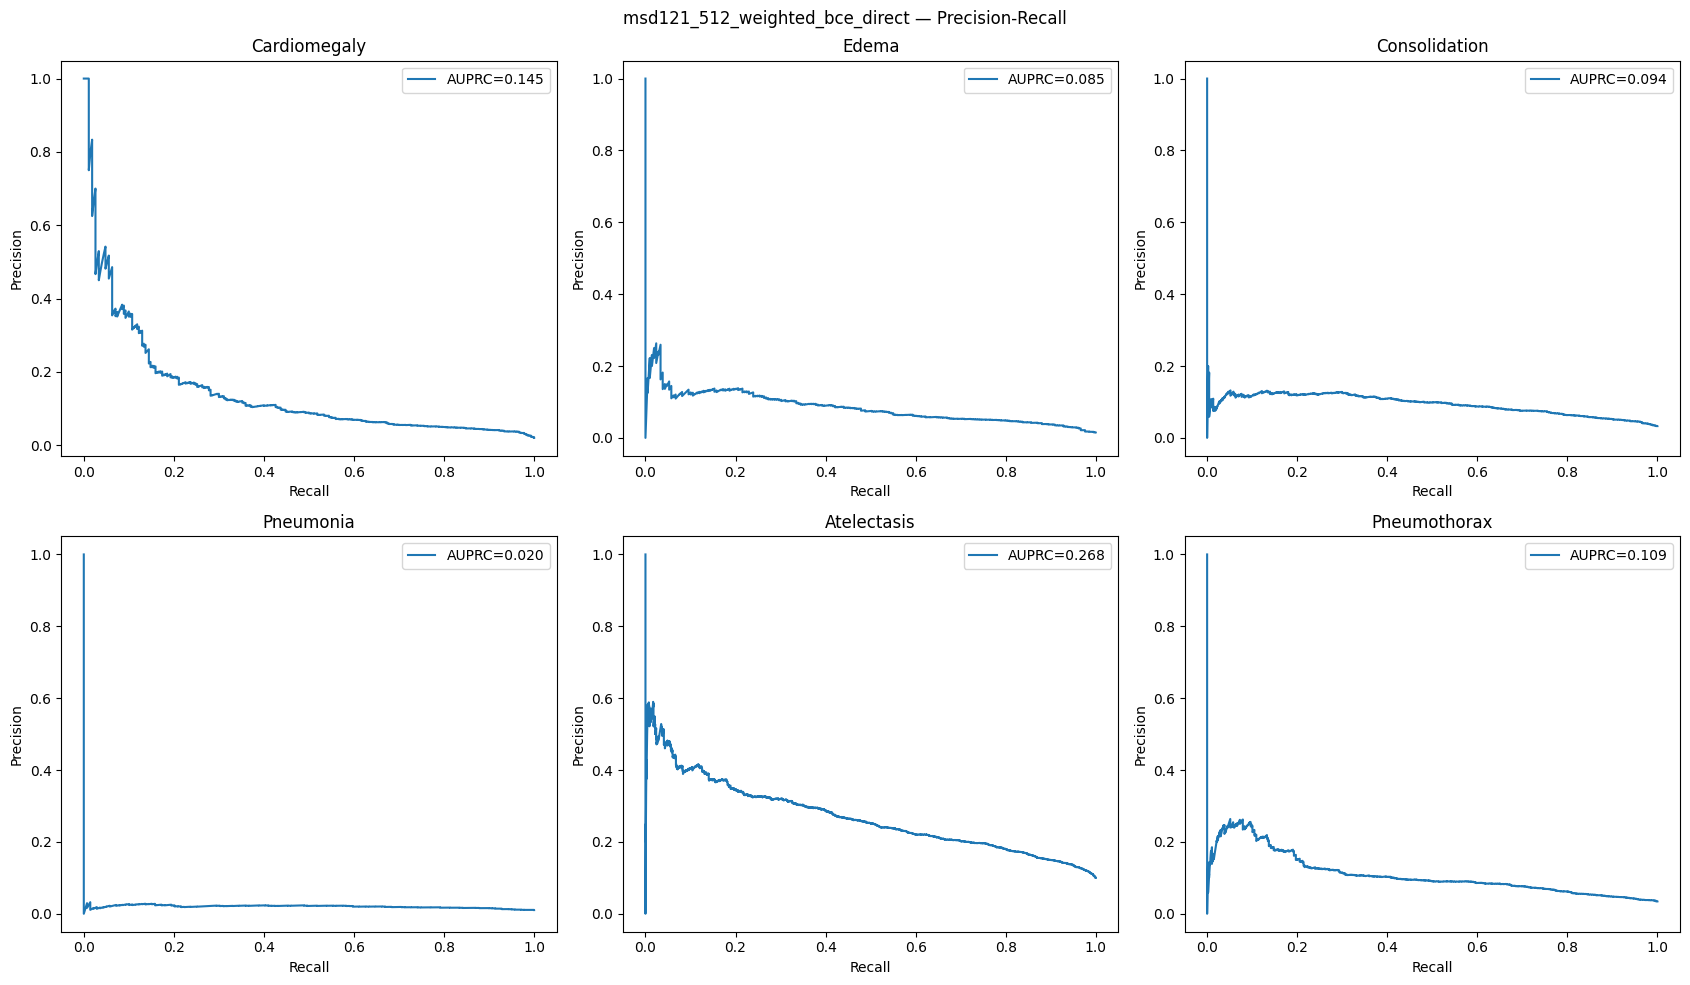

In [9]:
def per_class_metrics(y_true, y_prob, thresholds=None):
    rows = []
    if thresholds is None:
        thresholds = np.full(len(LABELS), 0.5, dtype=float)
    for j, label in enumerate(LABELS):
        yt, yp = y_true[:, j], y_prob[:, j]
        row = {"label": label, "positive_count": int(yt.sum()), "negative_count": int((1-yt).sum())}
        row["auroc"] = roc_auc_score(yt, yp) if len(np.unique(yt)) == 2 else np.nan
        row["auprc"] = average_precision_score(yt, yp) if yt.sum() > 0 else np.nan
        pred = (yp >= thresholds[j]).astype(int)
        tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0,1]).ravel()
        row.update({
            "threshold": float(thresholds[j]),
            "precision": precision_score(yt, pred, zero_division=0),
            "recall_sensitivity": recall_score(yt, pred, zero_division=0),
            "f1": f1_score(yt, pred, zero_division=0),
            "specificity": tn/(tn+fp) if (tn+fp) else np.nan,
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)
        })
        rows.append(row)
    return pd.DataFrame(rows)

metric_tables = {}
for exp_id, (yt, yp, names) in predictions.items():
    m = per_class_metrics(yt, yp)
    m.insert(0, "experiment_id", exp_id)
    metric_tables[exp_id] = m
    m.to_csv(OUTPUT_DIR / f"{exp_id}_per_disease_metrics.csv", index=False)

all_metrics = pd.concat(metric_tables.values(), ignore_index=True)
display(all_metrics)
all_metrics.to_csv(OUTPUT_DIR / "all_models_per_disease_metrics.csv", index=False)

# ROC and precision-recall curves for each disease, saved per model.
for exp_id, (yt, yp, _) in predictions.items():
    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    for j, ax in enumerate(axes.flat):
        if len(np.unique(yt[:,j])) < 2:
            ax.set_title(f"{LABELS[j]} (single class)")
            continue
        fpr, tpr, _ = roc_curve(yt[:,j], yp[:,j])
        ax.plot(fpr, tpr, label=f"AUROC={roc_auc_score(yt[:,j], yp[:,j]):.3f}")
        ax.plot([0,1],[0,1], linestyle="--")
        ax.set_title(LABELS[j]); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend()
    fig.suptitle(f"{exp_id} — ROC")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{exp_id}_roc.png", dpi=140)
    plt.show(); plt.close(fig)

    fig, axes = plt.subplots(2, 3, figsize=(17, 10))
    for j, ax in enumerate(axes.flat):
        p, r, _ = precision_recall_curve(yt[:,j], yp[:,j])
        ap = average_precision_score(yt[:,j], yp[:,j])
        ax.plot(r, p, label=f"AUPRC={ap:.3f}")
        ax.set_title(LABELS[j]); ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend()
    fig.suptitle(f"{exp_id} — Precision-Recall")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{exp_id}_pr.png", dpi=140)
    plt.show(); plt.close(fig)


## 9. Validation threshold selection (per-label F1; do not use test labels)

In [10]:
def select_f1_thresholds(y_true, y_prob):
    rows, thresholds = [], []
    grid = np.linspace(0.01, 0.99, 99)
    for j, label in enumerate(LABELS):
        best = (-1, 0.5)
        for t in grid:
            pred = (y_prob[:,j] >= t).astype(int)
            score = f1_score(y_true[:,j], pred, zero_division=0)
            if score > best[0]:
                best = (score, float(t))
        thresholds.append(best[1])
        rows.append({"label": label, "selected_threshold": best[1], "validation_f1_at_threshold": best[0]})
    return np.array(thresholds), pd.DataFrame(rows)

threshold_outputs = {}
for exp_id, (yt, yp, _) in predictions.items():
    th, tab = select_f1_thresholds(yt, yp)
    threshold_outputs[exp_id] = th
    tab.insert(0, "experiment_id", exp_id)
    tab.to_csv(OUTPUT_DIR / f"{exp_id}_thresholds.csv", index=False)
    print(exp_id); display(tab)


msd121_224_weighted_bce_direct


,experiment_id,label,selected_threshold,validation_f1_at_threshold
0,msd121_224_weighted_bce_direct,Cardiomegaly,0.87,0.291022
1,msd121_224_weighted_bce_direct,Edema,0.94,0.224256
2,msd121_224_weighted_bce_direct,Consolidation,0.79,0.193680
3,msd121_224_weighted_bce_direct,Pneumonia,0.55,0.070768
4,msd121_224_weighted_bce_direct,Atelectasis,0.67,0.367996
5,msd121_224_weighted_bce_direct,Pneumothorax,0.77,0.246619


msd121_224_weighted_bce_letterbox


,experiment_id,label,selected_threshold,validation_f1_at_threshold
0,msd121_224_weighted_bce_letterbox,Cardiomegaly,0.74,0.295195
1,msd121_224_weighted_bce_letterbox,Edema,0.86,0.208571
2,msd121_224_weighted_bce_letterbox,Consolidation,0.80,0.195411
3,msd121_224_weighted_bce_letterbox,Pneumonia,0.72,0.079019
4,msd121_224_weighted_bce_letterbox,Atelectasis,0.66,0.362447
5,msd121_224_weighted_bce_letterbox,Pneumothorax,0.78,0.271261


msd121_224_focal_direct


,experiment_id,label,selected_threshold,validation_f1_at_threshold
0,msd121_224_focal_direct,Cardiomegaly,0.69,0.314371
1,msd121_224_focal_direct,Edema,0.61,0.188679
2,msd121_224_focal_direct,Consolidation,0.62,0.188758
3,msd121_224_focal_direct,Pneumonia,0.48,0.056834
4,msd121_224_focal_direct,Atelectasis,0.57,0.369413
5,msd121_224_focal_direct,Pneumothorax,0.58,0.244713


msd121_224_focal_letterbox


,experiment_id,label,selected_threshold,validation_f1_at_threshold
0,msd121_224_focal_letterbox,Cardiomegaly,0.79,0.258407
1,msd121_224_focal_letterbox,Edema,0.69,0.204444
2,msd121_224_focal_letterbox,Consolidation,0.55,0.160477
3,msd121_224_focal_letterbox,Pneumonia,0.52,0.060561
4,msd121_224_focal_letterbox,Atelectasis,0.55,0.332260
5,msd121_224_focal_letterbox,Pneumothorax,0.58,0.216511


msd121_512_weighted_bce_direct


,experiment_id,label,selected_threshold,validation_f1_at_threshold
0,msd121_512_weighted_bce_direct,Cardiomegaly,0.13,0.198601
1,msd121_512_weighted_bce_direct,Edema,0.16,0.165067
2,msd121_512_weighted_bce_direct,Consolidation,0.11,0.174843
3,msd121_512_weighted_bce_direct,Pneumonia,0.02,0.044042
4,msd121_512_weighted_bce_direct,Atelectasis,0.14,0.336315
5,msd121_512_weighted_bce_direct,Pneumothorax,0.15,0.182190


## 10. Calibration diagnostics

In [11]:
# Reliability-bin tables and Brier scores. This is diagnostic only; do not fit calibration
# on the official test set. If fitting Platt/isotonic calibration, fit on validation
# and disclose that validation is then used for both model selection and calibration.
def calibration_table(y_true, y_prob, n_bins=10):
    rows = []
    edges = np.linspace(0, 1, n_bins+1)
    for j, label in enumerate(LABELS):
        for b in range(n_bins):
            lo, hi = edges[b], edges[b+1]
            mask = (y_prob[:,j] >= lo) & ((y_prob[:,j] < hi) if b < n_bins-1 else (y_prob[:,j] <= hi))
            if mask.any():
                rows.append({
                    "label": label, "bin": b, "count": int(mask.sum()),
                    "mean_probability": float(y_prob[mask,j].mean()),
                    "observed_frequency": float(y_true[mask,j].mean())
                })
    return pd.DataFrame(rows)

calibration_outputs = []
for exp_id, (yt, yp, _) in predictions.items():
    cal = calibration_table(yt, yp)
    cal.insert(0, "experiment_id", exp_id)
    cal["brier_score"] = [brier_score_loss(yt[:,j], yp[:,j]) for j in range(len(LABELS)) for _ in range(0)] if False else np.nan
    calibration_outputs.append(cal)
    cal.to_csv(OUTPUT_DIR / f"{exp_id}_calibration_bins.csv", index=False)
    brier = pd.DataFrame({"label": LABELS, "brier_score": [brier_score_loss(yt[:,j], yp[:,j]) for j in range(len(LABELS))]})
    brier.insert(0, "experiment_id", exp_id)
    brier.to_csv(OUTPUT_DIR / f"{exp_id}_brier_scores.csv", index=False)


## 11. Final model selection record

Choose a model using validation metrics, class-wise performance, calibration, inference cost and clinical limitations—not macro-AUROC alone. The leading historical candidate is 224 Weighted BCE Direct, but final selection should wait until all validation inference outputs are reviewed.

Do not describe this research model as a diagnostic replacement for a radiologist. Report it as an experimental multi-label classification system, with limitations around dataset labels, prevalence, domain shift and external validation.


In [12]:
# Create a compact machine-readable run summary.
summary = {
    "project": "LungVision AI Phase 7",
    "evaluation_split": "validation_only",
    "official_test_evaluated": False,
    "training_performed": False,
    "expected_split_sha256": EXPECTED_SPLIT_SHA256,
    "labels": LABELS,
    "output_dir": str(OUTPUT_DIR),
    "historical_leading_candidate": str(best_row["experiment_id"]),
    "historical_best_validation_macro_auroc": float(best_row["best_val_macro_auroc"]),
    "inference_completed": bool("predictions" in globals() and len(predictions) > 0),
    "note": "Exact original model and preprocessing source embedded; validation-only inference."
}
(OUTPUT_DIR / "evaluation_run_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))
print("Outputs saved to:", OUTPUT_DIR)


{
  "project": "LungVision AI Phase 7",
  "evaluation_split": "validation_only",
  "official_test_evaluated": false,
  "training_performed": false,
  "expected_split_sha256": "ca0d2ed9efe6c4a2b479b25d5c10e762bdffcda1eeaf5672fcca499e6ddb7a09",
  "labels": [
    "Cardiomegaly",
    "Edema",
    "Consolidation",
    "Pneumonia",
    "Atelectasis",
    "Pneumothorax"
  ],
  "output_dir": "/kaggle/working/lungvision_phase7_final_evaluation",
  "historical_leading_candidate": "msd121_224_weighted_bce_direct",
  "historical_best_validation_macro_auroc": 0.8197257752392035,
  "inference_completed": true,
  "note": "Exact original model and preprocessing source embedded; validation-only inference."
}
Outputs saved to: /kaggle/working/lungvision_phase7_final_evaluation


## 12. Export results

After all inference and metrics cells complete, create a ZIP for download from Kaggle Output:

```python
import shutil
zip_path = shutil.make_archive(
    "/kaggle/working/lungvision_phase7_final_evaluation",
    "zip",
    root_dir=OUTPUT_DIR
)
print(zip_path)
```

Download the ZIP from the Kaggle notebook's Output panel and retain it with the original checkpoints. The official test set remains untouched.
